# Rapport — Engine de traitement et d'analyse de flux de données sécurisé

**Projet final ING3 — Python 3.10+**
Auteurs : *Nom 1, Nom 2, Nom 3* (trinôme)

Ce notebook illustre le fonctionnement du package `logstream`. Il ne contient
**aucune logique métier** : tout le code de traitement est dans les modules
`.py` du package, le notebook se contente de les importer, de les exécuter et
d'afficher les résultats sous forme de graphiques (conformément à la consigne :
notebooks réservés à l'expérimentation et à la démonstration graphique).

**Sommaire**
1. Environnement et architecture
2. Module 1 — Ingestion & générateurs mémoire
3. Module 2 — Pipeline fonctionnel & pattern matching
4. Module 3 — Agrégation, ensembles et détection de force brute
5. Module 4 — Moteur de règles & introspection
6. Étude mémoire : générateur vs liste
7. Conclusion

## 1. Environnement et architecture

In [1]:
import sys
from pathlib import Path

# Le notebook est dans notebooks/ : on ajoute la racine du projet au path.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

print("Python             :", sys.version.split()[0])
print("Environnement isolé :", sys.prefix != sys.base_prefix, f"({sys.prefix})")

Python             : 3.13.5
Environnement isolé : True (/home/benjamin/Téléchargements/projet_python/.venv)


```
projet_python/
├── main.py                  # point d'entrée CLI : pilote tout le pipeline
├── requirements.txt         # généré par pip freeze
├── logstream/               # package Python
│   ├── config.py            # constantes (frozenset, tuples)
│   ├── models.py            # types : LogRecord (dict), ConnectionMeta (tuple)
│   ├── exceptions.py        # exceptions personnalisées
│   ├── ingestion.py         # Module 1 : yield / yield from
│   ├── parsing.py           # Module 1 : parsing en dictionnaires
│   ├── pipeline.py          # Module 2 : map / filter / lambda / match-case
│   ├── aggregation.py       # Module 3 : set / frozenset / defaultdict
│   ├── detection.py         # Module 3 : force brute (while / for / else)
│   ├── rules.py             # Module 4 : *args / **kwargs
│   ├── audit.py             # Module 4 : globals() / locals()
│   ├── simulator.py         # génération du jeu de test
│   └── reporting.py         # affichage et export JSON
├── scripts/generate_dataset.py
├── data/                    # jeu de données de test fourni
├── tests/                   # tests unitaires pytest
└── notebooks/rapport.ipynb  # ce rapport
```

In [2]:
import matplotlib.pyplot as plt

# Charte graphique commune à tous les graphiques du rapport.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
LEVEL_COLORS = {"INFO": BLUE, "WARNING": "#fab219",
                "ERROR": "#ec835a", "CRITICAL": "#d03b3b"}

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": MUTED,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "lines.linewidth": 2,
})


def hbar(labels, values, title, color=BLUE, xlabel=""):
    """Barres horizontales avec étiquettes de valeur."""
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(labels) + 1))
    colors = color if isinstance(color, list) else [color] * len(labels)
    bars = ax.barh(labels, values, color=colors, height=0.6)
    ax.bar_label(bars, padding=4, color=MUTED, fontsize=9)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.12)
    plt.show()

## 2. Module 1 — Ingestion & générateurs mémoire

`read_log_file` est un **générateur** (`yield`) : l'appeler ne lit rien, il
renvoie un objet qui produira les lignes une par une, à la demande.
`read_log_sources` enchaîne plusieurs fichiers avec **`yield from`**.

In [3]:
import inspect
from logstream.config import DATA_DIR, DEFAULT_LOG_FILES
from logstream.ingestion import read_log_file, read_log_sources

PATHS = [DATA_DIR / name for name in DEFAULT_LOG_FILES]

lines = read_log_file(PATHS[0])
print("Type :", type(lines).__name__, "| générateur ?", inspect.isgenerator(lines))
print("Taille de l'objet générateur :", sys.getsizeof(lines), "octets")
print("Taille du fichier             :", PATHS[0].stat().st_size, "octets")
print("Première ligne :", next(lines))
lines.close()  # on libère le fichier

total = sum(1 for _ in read_log_sources(PATHS))  # parcours sans liste
print(f"\n{total} lignes lues dans {len(PATHS)} fichiers via yield from")

Type : generator | générateur ? True
Taille de l'objet générateur : 264 octets
Taille du fichier             : 619249 octets
Première ligne : 2026-10-20T06:00:01 | INFO | 192.168.1.25:443/TCP | user008 | {"method": "GET", "path": "/index.html", "status": 200}

15225 lignes lues dans 3 fichiers via yield from


**Parsing.** Chaque ligne devient un **dictionnaire** typé : `datetime` pour
l'horodatage, `str` pour le niveau, **tuple immuable** `(IP, Port, Protocole)`
pour la source, `dict` (JSON) ou `str` pour le payload.

In [4]:
from pprint import pprint
from logstream.parsing import decode_line, parse_text_line

record = parse_text_line(
    '2026-10-20T08:15:32 | WARNING | 203.0.113.7:22/SSH | root | '
    '{"event": "login", "status": "failed"}'
)
pprint(record, sort_dicts=False)
print("\nsource est un tuple :", isinstance(record["source"], tuple))

for line in ['{"timestamp": "2026-10-20T08:00:00", "level": "ERROR", "code": 500, "ip": "10.0.0.3"}',
             "CONN 2026-10-20T08:00:10 203.0.113.66 23 TCP",
             "2026-10-20T08:00:20 | CRITICAL | 10.0.0.1:0/UDP | - | Disque plein"]:
    decoded = decode_line(line)
    print(f"{type(decoded).__name__:>5} <- {line[:60]}")

{'timestamp': datetime.datetime(2026, 10, 20, 8, 15, 32),
 'level': 'WARNING',
 'source': ('203.0.113.7', 22, 'SSH'),
 'ip': '203.0.113.7',
 'user_id': 'root',
 'payload': {'event': 'login', 'status': 'failed'},
 'category': 'AUTH',
 'origin_format': 'raw',
 'message': ''}

source est un tuple : True
 dict <- {"timestamp": "2026-10-20T08:00:00", "level": "ERROR", "code
tuple <- CONN 2026-10-20T08:00:10 203.0.113.66 23 TCP
  str <- 2026-10-20T08:00:20 | CRITICAL | 10.0.0.1:0/UDP | - | Disque


## 3. Module 2 — Pipeline fonctionnel & pattern matching

`build_pipeline` chaîne des `map()` et `filter()` (avec `lambda` et
`filter(None, ...)`). La fonction `route_entry` utilise un **`match-case`**
pour router chaque entrée selon son format : chaîne brute, dictionnaire
`{'level': ..., 'code': ...}` ou tuple de connexion.

In [5]:
from datetime import datetime
from logstream.pipeline import route_entry

samples = [
    "2026-10-20T08:00:00 | INFO | 10.0.0.2:443/TCP | bob | Service démarré",
    {"timestamp": "2026-10-20T08:00:05", "level": "ERROR", "code": 503, "ip": "10.0.0.3"},
    (datetime(2026, 10, 20, 8, 0, 10), "203.0.113.66", 3389, "TCP"),
    ("10.0.0.9", 22, "SSH"),
    "ligne corrompue",
    12345,
]
for sample in samples:
    result = route_entry(sample)
    status = f"{result['origin_format']:<5} -> {result['category']}" if result else "rejetée (None)"
    print(f"{type(sample).__name__:>8} | {status}")

     str | raw   -> SYSTEM
    dict | dict  -> HTTP
   tuple | tuple -> NETWORK
   tuple | tuple -> NETWORK
     str | rejetée (None)
     int | rejetée (None)


In [6]:
from itertools import islice
from logstream.pipeline import PipelineMetrics, build_pipeline

metrics = PipelineMetrics()
pipeline = build_pipeline(read_log_sources(PATHS), metrics)
print("Avant consommation :", dict(metrics.counters), "(rien n'est calculé)")

for rec in islice(pipeline, 3):
    print(rec["message"])

for _ in pipeline:  # on consomme la suite
    pass
pprint(metrics.as_dict())

Avant consommation : {} (rien n'est calculé)
[2026-10-20 06:00:01] INFO        192.168.1.25:443   TCP   user=user008    HTTP    GET /index.html -> 200
[2026-10-20 06:00:04] ERROR      198.51.100.99:443   TCP   user=user020    HTTP    code 504 : Erreur serveur HTTP 504
[2026-10-20 06:00:23] INFO        192.168.1.10:80    TCP   user=user025    HTTP    GET /dashboard -> 200
{'non_empty_entries': 15137,
 'parsed_records': 15036,
 'raw_entries': 15225,
 'rejected': 131,
 'valid_records': 15006}


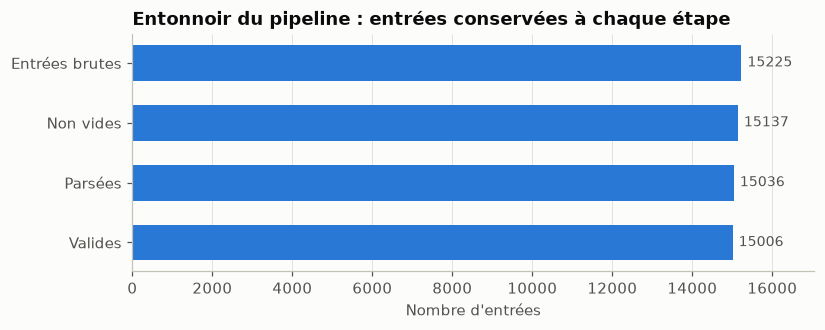

In [7]:
c = metrics.counters
hbar(["Entrées brutes", "Non vides", "Parsées", "Valides"],
     [c["raw_entries"], c["non_empty_entries"], c["parsed_records"], c["valid_records"]],
     "Entonnoir du pipeline : entrées conservées à chaque étape",
     xlabel="Nombre d'entrées")

## 4. Module 3 — Agrégation et traitement avancé

Un seul passage sur le flux alimente des compteurs `defaultdict(int)` (aucun
`KeyError` possible) et des `set` d'IP. Les tuples `(IP, Port, Protocole)`
étant hachables, on peut aussi en faire un ensemble de connexions uniques.

In [8]:
from logstream.aggregation import collect_statistics, compare_ip_sets, analyze_error_ips, top_n
from logstream.config import SEVERITY_ORDER
from logstream.ingestion import load_blacklist

stats = collect_statistics(build_pipeline(read_log_sources(PATHS)))
blacklist = load_blacklist(DATA_DIR / "blacklist.txt")

print("Type des compteurs :", type(stats.by_level).__name__)
print("Niveau jamais vu   :", stats.by_level["DEBUG"], "(pas de KeyError)")
print("IP actives         :", len(stats.active_ips))
print("IP en erreur       :", len(stats.error_ips))
print("Connexions uniques :", len(stats.connections), "ex.", next(iter(stats.connections)))
print("Liste noire        :", type(blacklist).__name__, sorted(blacklist))

Type des compteurs : defaultdict
Niveau jamais vu   : 0 (pas de KeyError)
IP actives         : 46
IP en erreur       : 14
Connexions uniques : 276 ex. ('10.0.0.3', 443, 'TCP')
Liste noire        : frozenset ['185.220.101.4', '198.51.100.23', '203.0.113.66', '45.33.32.156', '91.189.0.17']


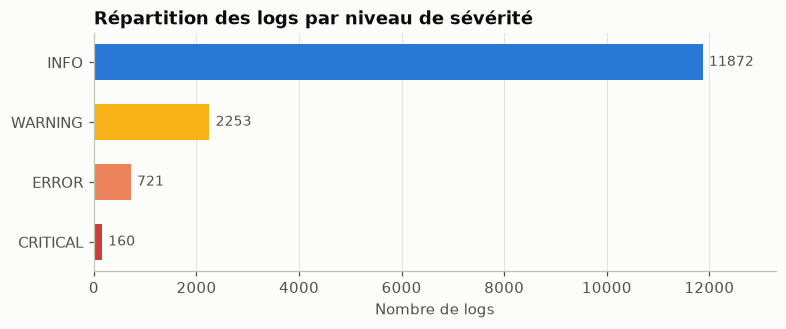

In [9]:
hbar(list(SEVERITY_ORDER), [stats.by_level[l] for l in SEVERITY_ORDER],
     "Répartition des logs par niveau de sévérité",
     color=[LEVEL_COLORS[l] for l in SEVERITY_ORDER], xlabel="Nombre de logs")

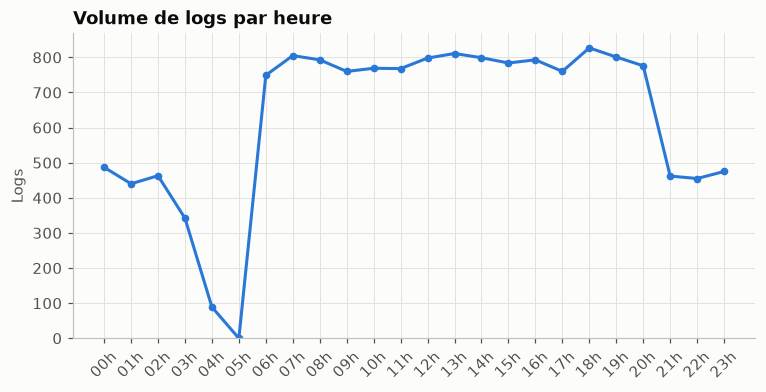

In [10]:
hours = [f"{h:02d}h" for h in range(24)]  # toutes les heures, même vides
fig, ax = plt.subplots()
ax.plot(hours, [stats.by_hour.get(h, 0) for h in hours], color=BLUE, marker="o", markersize=4)
ax.set_title("Volume de logs par heure")
ax.set_ylabel("Logs")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=45)
plt.show()

**Opérations ensemblistes** entre les IP actives (`set`) et la liste noire
(`frozenset` immuable) : union `|`, intersection `&`, différences `-` et
différence symétrique `^`.

union                     48  ['10.0.0.1', '10.0.0.10', '10.0.0.11']
intersection               3  ['185.220.101.4', '198.51.100.23', '203.0.113.66']
active_not_blacklisted    43  ['10.0.0.1', '10.0.0.10', '10.0.0.11']
blacklisted_inactive       2  ['45.33.32.156', '91.189.0.17']
symmetric_difference      45  ['10.0.0.1', '10.0.0.10', '10.0.0.11']

frozenset({'198.51.100.23', '185.220.101.4', '203.0.113.66'})


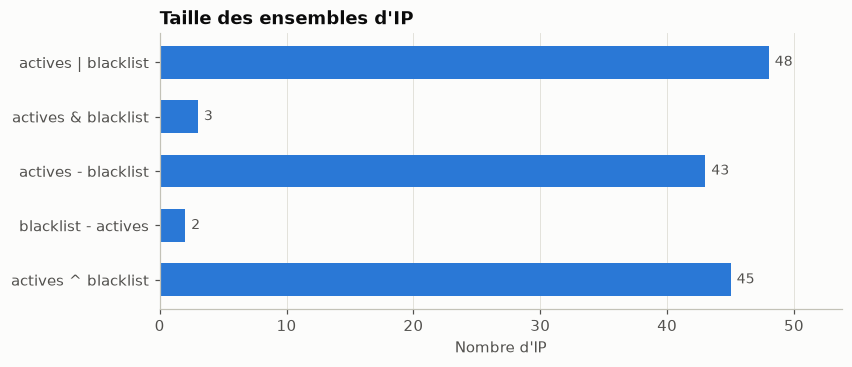

In [11]:
ip_sets = compare_ip_sets(stats.active_ips, blacklist)
for name, values in ip_sets.items():
    print(f"{name:<24} {len(values):>3}  {sorted(values)[:3]}")

print()
pprint(analyze_error_ips(stats.error_ips, blacklist)["known_threats"])

labels = {"union": "actives | blacklist", "intersection": "actives & blacklist",
          "active_not_blacklisted": "actives - blacklist",
          "blacklisted_inactive": "blacklist - actives",
          "symmetric_difference": "actives ^ blacklist"}
hbar([labels[k] for k in ip_sets], [len(v) for v in ip_sets.values()],
     "Taille des ensembles d'IP", xlabel="Nombre d'IP")

**Détection de force brute.** La boucle `while` découpe le flux en lots
(cycles), la boucle `for` traite chaque événement ; `continue` saute les
événements non pertinents, `break` arrête l'analyse si `max_alerts` est
atteint, et les clauses `else` des deux boucles valident respectivement
qu'un cycle et que toute l'analyse se sont terminés sans interruption.

Limite de 3 alertes atteinte : arrêt


Analyse complète : True | cycles complets : 31
Échecs de connexion : 1601 | attaques : 70
  -   198.51.100.23 : 5 échecs en 12s sur user001
  -   198.51.100.23 : 5 échecs en 11s sur backup
  -   198.51.100.99 : 5 échecs en 11s sur admin
  -     203.0.113.7 : 5 échecs en 8s sur backup
  -   198.51.100.23 : 5 échecs en 8s sur admin



Avec max_alerts=3 -> complète : False (5337 événements traités sur 15006)


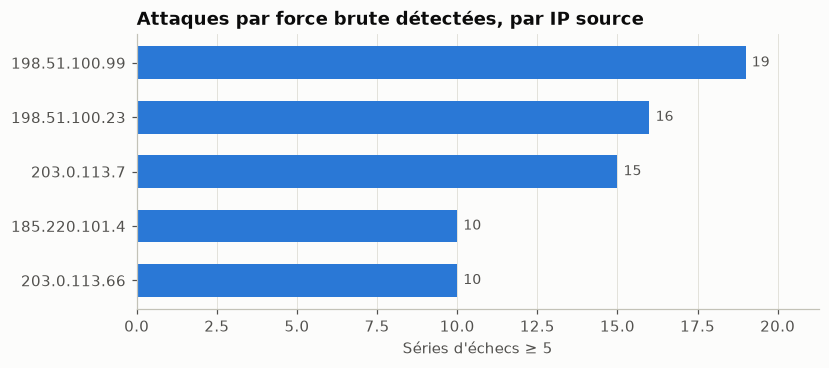

In [12]:
from logstream.aggregation import count_by
from logstream.detection import detect_brute_force

result = detect_brute_force(build_pipeline(read_log_sources(PATHS)), threshold=5)
print(f"Analyse complète : {result.complete} | cycles complets : {result.completed_cycles}")
print(f"Échecs de connexion : {result.failed_logins} | attaques : {len(result.alerts)}")
for alert in result.alerts[:5]:
    print("  -", alert)

partial = detect_brute_force(build_pipeline(read_log_sources(PATHS)), max_alerts=3)
print(f"\nAvec max_alerts=3 -> complète : {partial.complete} "
      f"({partial.processed_events} événements traités sur {result.processed_events})")

per_ip = top_n(count_by(result.alerts, lambda alert: alert.ip), 10)
hbar([ip for ip, _ in per_ip], [n for _, n in per_ip],
     "Attaques par force brute détectées, par IP source", xlabel="Séries d'échecs ≥ 5")

## 5. Module 4 — Moteur de règles & introspection

`apply_security_rules(*args, **kwargs)` reçoit les règles (fonctions passées
comme objets de première classe) dans `*args` et la configuration dans
`**kwargs`. On peut lui passer n'importe quelle fonction, y compris une règle
écrite à la volée.

Règles découvertes via globals() : ['rule_blacklisted_ip', 'rule_critical_event', 'rule_suspicious_port', 'rule_injection_attempt', 'rule_off_hours_error']
Paramètres transmis aux règles : {'blacklist': 'frozenset'}
Logs contrôlés : 15006 | alertes : 2286


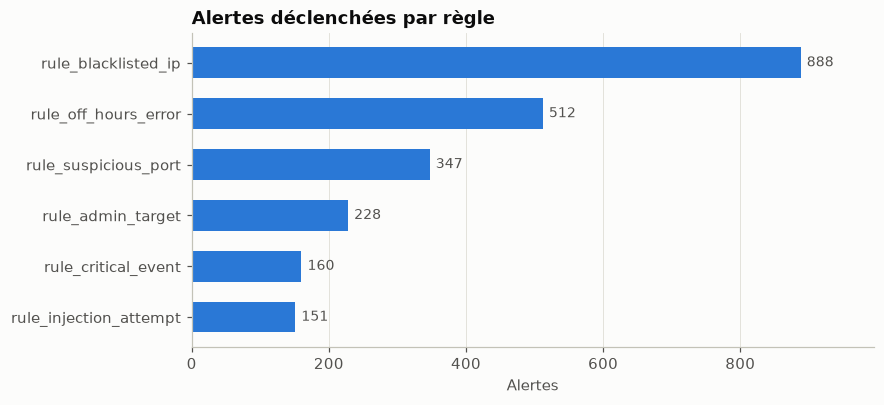

In [13]:
from logstream.rules import apply_security_rules, available_rules, make_off_hours_rule

print("Règles découvertes via globals() :", list(available_rules()))

# Règle personnalisée : une lambda passée en argument comme les autres.
rule_admin = lambda record, **_: "Compte admin ciblé" if record["user_id"] == "admin" else None
rule_admin.__name__ = "rule_admin_target"

report = apply_security_rules(
    *available_rules().values(), rule_admin, make_off_hours_rule(8, 18),
    records=build_pipeline(read_log_sources(PATHS)),
    blacklist=blacklist,
)
print("Paramètres transmis aux règles :", report.config)
print("Logs contrôlés :", report.records_checked, "| alertes :", report.total_hits)

hits = top_n(report.hits_by_rule, 10)
hbar([name for name, _ in hits], [n for _, n in hits],
     "Alertes déclenchées par règle", xlabel="Alertes")

**Audit.** `export_audit_report` inspecte des portées passées en argument
(`globals()`, `locals()`) et exporte, pour chaque variable, son type, sa taille
mémoire et un aperçu.

In [14]:
from logstream.audit import build_audit_report, format_scope_table


def exemple_fonction():
    seuil = 5
    ips_suspectes = {"203.0.113.7", "198.51.100.99"}
    flux = build_pipeline(read_log_sources(PATHS))  # générateur : quelques octets
    return build_audit_report(fonction_locals=locals())


audit = build_audit_report(notebook_globals=globals())
print(format_scope_table(audit["scopes"]["notebook_globals"]["variables"], limit=10))
print()
print(format_scope_table(exemple_fonction()["scopes"]["fonction_locals"]["variables"]))

Variable                 Type                 Taille (o)
--------------------------------------------------------
AXIS                     str                          48
BLUE                     str                          48
DATA_DIR                 PosixPath                   112
DEFAULT_LOG_FILES        tuple                        64
GRID                     str                          48
INK                      str                          48
In                       list                        184
LEVEL_COLORS             dict                        184
MUTED                    str                          48
ORANGE                   str                          48
... (61 autres variables)

Variable                 Type                 Taille (o)
--------------------------------------------------------
flux                     generator                   232
ips_suspectes            set                         216
seuil                    int                          28


## 6. Étude mémoire : générateur vs liste

On génère des fichiers de taille croissante, puis on mesure le pic mémoire
(`tracemalloc`) de deux façons de les traiter :

* **liste** : `list(...)` charge tous les enregistrements en RAM ;
* **générateur** : le pipeline paresseux, consommé au fil de l'eau.

In [15]:
import tempfile
import tracemalloc
from logstream.simulator import generate_auth_lines, write_lines


def peak_kib(func):
    tracemalloc.start()
    func()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024


sizes, list_peaks, gen_peaks = [], [], []
with tempfile.TemporaryDirectory() as tmp:
    for n in (2_000, 5_000, 10_000, 20_000):
        path = Path(tmp) / f"auth_{n}.log"
        write_lines(path, generate_auth_lines(n))
        sizes.append(n)
        list_peaks.append(peak_kib(lambda: list(build_pipeline(read_log_file(path)))))
        gen_peaks.append(peak_kib(lambda: collect_statistics(build_pipeline(read_log_file(path)))))
        print(f"{n:>7} lignes : liste {list_peaks[-1]:>9.0f} Kio | générateur {gen_peaks[-1]:>6.0f} Kio")

   2000 lignes : liste      2072 Kio | générateur     40 Kio


   5000 lignes : liste      5197 Kio | générateur     46 Kio


  10000 lignes : liste     10509 Kio | générateur     44 Kio


  20000 lignes : liste     21190 Kio | générateur     64 Kio


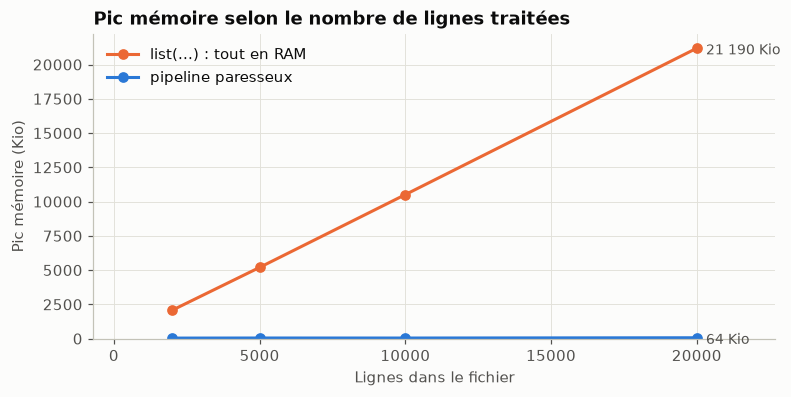

In [16]:
fig, ax = plt.subplots()
ax.plot(sizes, list_peaks, color=ORANGE, marker="o", label="list(...) : tout en RAM")
ax.plot(sizes, gen_peaks, color=BLUE, marker="o", label="pipeline paresseux")
for series, color in ((list_peaks, ORANGE), (gen_peaks, BLUE)):
    ax.annotate(f"{series[-1]:,.0f} Kio".replace(",", " "), (sizes[-1], series[-1]),
                textcoords="offset points", xytext=(6, -4), color=MUTED, fontsize=9)
ax.set_title("Pic mémoire selon le nombre de lignes traitées")
ax.set_xlabel("Lignes dans le fichier")
ax.set_ylabel("Pic mémoire (Kio)")
ax.set_ylim(bottom=0)
ax.margins(x=0.15)
ax.legend(frameon=False, loc="upper left")
plt.show()

La consommation de la version « liste » croît linéairement avec le volume,
alors que celle du pipeline paresseux reste **quasi constante** : seuls les
compteurs et les ensembles d'IP distinctes sont conservés. Sur le jeu
complet, `main.py` passe de 15 000 à 450 000 lignes avec un pic qui reste
autour de 1 à 2 Mo.

## 7. Conclusion

| Exigence du cahier des charges | Implémentation |
|---|---|
| Générateur `yield` ligne par ligne | `ingestion.read_log_file` |
| Sous-générateur `yield from` | `ingestion.read_log_sources`, `read_streams` |
| Lignes parsées en dictionnaires typés | `parsing.parse_text_line` / `parse_dict_entry` |
| Tuples pour les métadonnées fixes | `ConnectionMeta = (IP, Port, Protocole)` |
| `filter()` + `lambda`, `filter(None, ...)` | `pipeline.build_pipeline`, `VALIDATORS` |
| `map()` de normalisation + f-strings | `pipeline.normalize_record` |
| `match-case` (str / dict / tuple) | `pipeline.route_entry` (+ `decode_line`, `categorize`) |
| `set` des IP en erreur | `aggregation.TrafficStatistics.error_ips` |
| `frozenset` + `| & - ^` | `aggregation.compare_ip_sets` |
| `defaultdict` | compteurs de `TrafficStatistics`, `count_by`, détection |
| `while` + `for` + `break` / `continue` / `else` | `detection.detect_brute_force` |
| `apply_security_rules(*args, **kwargs)` | `rules.apply_security_rules` |
| Fonctions de première classe | règles, `VALIDATORS`, `chain_transforms`, closures |
| `globals()` / `locals()` | `audit.build_audit_report`, `rules.available_rules` |